# Capitolo 1 — Formazione e rappresentazione delle immagini
Arcangelo Distante e Cosimo Distante — **Computer Vision**

Questo notebook usa esclusivamente segnali, punti e camere sintetici, definiti nel codice. Non contiene immagini esterne, benchmark, addestramento o misure di una camera reale. Le quantità calcolate illustrano i modelli e le loro condizioni di validità.

## Avvio e materiali
In Google Colab aprire questo file, selezionare un runtime **CPU** e avviare le celle dall’alto. Non servono GPU, file da caricare né download di dati. Sono necessarie NumPy e Matplotlib, normalmente già disponibili in Colab; in un ambiente nuovo installarle prima dell’esecuzione con `%pip install numpy matplotlib`. In locale è adeguato Python 3 con le stesse dipendenze.

La cartella `output_capitolo01` viene creata nello stesso runtime. Alla fine contiene figure, eventuali CSV e `metriche.json`. Per conservarla in Colab scaricarla dal pannello File prima di chiudere il runtime, oppure copiarla nel proprio Drive dopo averlo montato. Il riavvio elimina le variabili: rieseguire dalla prima cella. Per ogni esperimento modificato conservare parametri, seed e output in una nuova cartella.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

OUTPUT = Path('output_capitolo01')
OUTPUT.mkdir(exist_ok=True)
rng = np.random.default_rng(2026)
metriche = {}
plt.rcParams.update({'font.size': 10, 'figure.figsize': (7, 4)})

def salva_figura(nome):
    plt.tight_layout()
    plt.savefig(OUTPUT / (nome + '.png'), dpi=160)
    plt.show()
    plt.close()

def proietta(P, X):
    q = np.c_[X, np.ones(len(X))] @ P.T
    return q[:, :2] / q[:, 2:]


## N1.A1 — Proiezione e ambiguità di scala

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

Pixel: [[440.         280.        ]
 [440.         280.        ]
 [266.66666667 320.        ]]
Errore dopo scala globale: 0.0


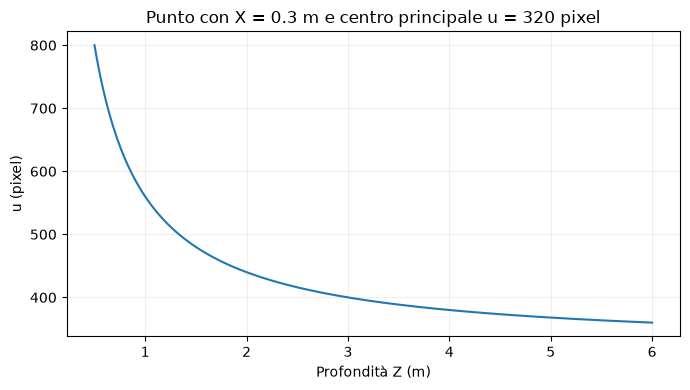

In [2]:
K = np.array([[800., 0, 320], [0, 800., 240], [0, 0, 1.]])
X = np.array([[0.3, 0.1, 2.], [0.6, 0.2, 4.], [-0.2, 0.3, 3.]])
P = K @ np.c_[np.eye(3), np.zeros(3)]
uv = proietta(P, X)
uv_scala = proietta(P, 2*X)
metriche['errore_invarianza_scala_pixel'] = float(np.max(np.abs(uv - uv_scala)))
print('Pixel:', uv)
print('Errore dopo scala globale:', metriche['errore_invarianza_scala_pixel'])
z = np.linspace(0.5, 6, 300)
plt.plot(z, 800*0.3/z + 320)
plt.xlabel('Profondità Z (m)'); plt.ylabel('u (pixel)')
plt.title('Punto con X = 0.3 m e centro principale u = 320 pixel')
plt.grid(alpha=0.2)
salva_figura('A1_proiezione')


**Domande**

1. Spiegare perché una scala globale lascia invariati i pixel.
2. Distinguere questo caso dal cambiamento della sola profondità Z.

## N1.A2 — Fotoni e rapporto segnale/rumore

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

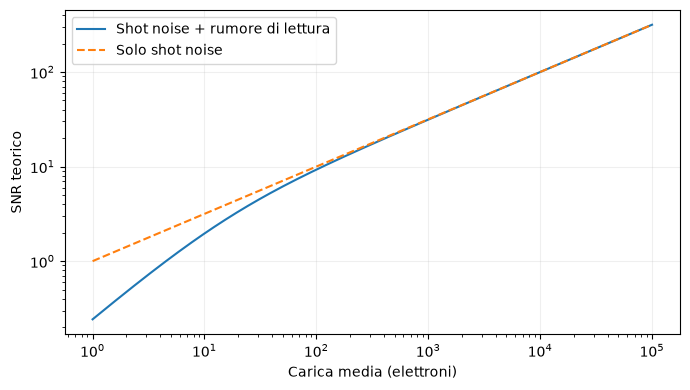

{'errore_invarianza_scala_pixel': 0.0, 'snr_400_elettroni': 19.611613513818405, 'snr_1600_elettroni': 39.80148760839957}


In [3]:
N = np.logspace(0, 5, 300)
sigma_lettura = 4.
snr = N / np.sqrt(N + sigma_lettura**2)
metriche['snr_400_elettroni'] = float(400 / np.sqrt(400 + sigma_lettura**2))
metriche['snr_1600_elettroni'] = float(1600 / np.sqrt(1600 + sigma_lettura**2))
plt.loglog(N, snr, label='Shot noise + rumore di lettura')
plt.loglog(N, np.sqrt(N), '--', label='Solo shot noise')
plt.xlabel('Carica media (elettroni)'); plt.ylabel('SNR teorico')
plt.legend(); plt.grid(alpha=0.2)
salva_figura('A2_snr')
print(metriche)


**Domande**

1. Interpretare il cambiamento di SNR fra 400 e 1600 elettroni.
2. Spiegare perché il guadagno elettronico non equivale a raccogliere più fotoni.

## N1.A3 — Campionamento e frequenze indistinguibili

Il codice realizza un esempio controllato. Prima di modificarne i parametri, descrivere le ipotesi del modello e le unità.

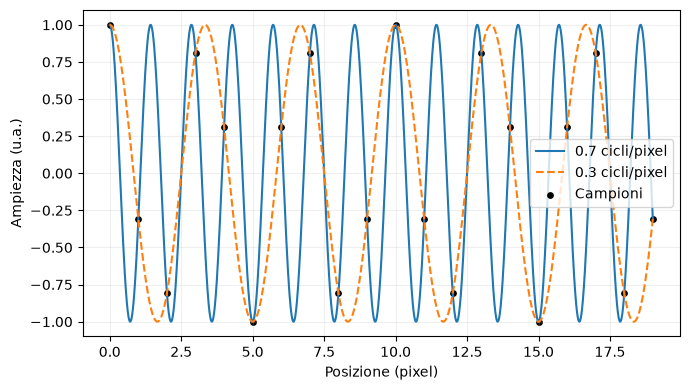

Differenza fra campioni: 6.772360450213455e-15


In [4]:
n = np.arange(20)
t = np.linspace(0, 19, 2000)
y1 = np.cos(2*np.pi*0.7*n)
y2 = np.cos(2*np.pi*0.3*n)
metriche['differenza_massima_campioni'] = float(np.max(np.abs(y1-y2)))
plt.plot(t, np.cos(2*np.pi*0.7*t), label='0.7 cicli/pixel')
plt.plot(t, np.cos(2*np.pi*0.3*t), '--', label='0.3 cicli/pixel')
plt.scatter(n, y1, s=15, color='black', label='Campioni')
plt.xlabel('Posizione (pixel)'); plt.ylabel('Ampiezza (u.a.)')
plt.legend(); plt.grid(alpha=0.2)
salva_figura('A3_aliasing')
print('Differenza fra campioni:', metriche['differenza_massima_campioni'])


**Domande**

1. Identificare la frequenza che supera Nyquist.
2. Discutere quale informazione possa recuperare un filtro applicato soltanto dopo il campionamento.

## Conservare i risultati

La cella seguente salva le quantità calcolate durante questa esecuzione. I valori del file descrivono questi dati sintetici e questi parametri. Non rappresentano prestazioni su dati reali.

In [5]:
with (OUTPUT / 'metriche.json').open('w') as f_json:
    json.dump(metriche, f_json, indent=2, allow_nan=False)
print('Output salvati in:', OUTPUT)

Output salvati in: output_capitolo01
